Business Problem
-----------------
A global e-commerce comppany operating across multiple regions manages end-to-end order fulfillment, including shipping and delivery, for products like sporting goods. The company is facing inconsistent delivery performance, where actual shipping times often deviate from scheduled timelines, leading to late deliveries and unpredictable order profitability.

Desired Outcome:
----------------
The goal is to analyze delivery operations, identify bottlenecks and build a predictive system to reduce delays, optimize shipping decisions, and improve overall profitability and efficiency

In [104]:
#loading all the nessary libraries......

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import matplotlib.ticker as ticker
import matplotlib.cm as cm
from warnings import filterwarnings
filterwarnings('ignore')

In [105]:
#loading the supply chain dataset....

df=pd.read_csv('DataCoSupplyChainDataset.csv', encoding="latin-1")

df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

In [106]:
df.head(6)

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class
5,TRANSFER,6,4,18.580000,294.980011,Shipping canceled,0,73,Sporting Goods,Tonawanda,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/19/2018 11:03,Standard Class


Exploratory Data Analysis(EDA)
------------------------------

In [107]:
# Overview

print('rows, cols:', df.shape)
print('\ncolumns;')
print(df.columns.to_list())
print('\nNum Duplicates:', df.duplicated().sum())
print('\nMissing values(top 20):')
print(df.isna().sum().sort_values(ascending=False).head(53))

rows, cols: (180519, 53)

columns;
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Produc

In [108]:
# Droping the columns which are not required for analysis

columns_to_drop = ['Product Description', 'Product Image','Customer Email','Customer Password','Customer Fname','Customer Lname','Customer Street','Customer Zipcode','Order Zipcode','Longitude','Latitude','Order Item Cardprod Id','Order Item Id','Order Item Discount','Order Item Discount Rate','Order Item Product Price','Order Item Quantity','Order Item Total','Category Id','Department Id','Order Id','Order Customer Id','Customer Id','Product Card Id','Product Category Id','Benefit per order','Product Status','Customer City','Order City','Order Country','Order State','Customer State','Market']

In [109]:
# Drop columns that are fully missing, redundant, or have only one unique value
df = df.drop(columns=columns_to_drop)

# Remove cancelled orders.....
df = df[df['Order Status'] != 'Shipping cancelled']

# Convert date columns to datetime
for c in ['order date (DateOrders)', 'shipping date (DateOrders)']:
    df[c] = pd.to_datetime(df[c], errors='coerce')

# Check dataset overview
print('Rows, Columns:', df.shape)

print('\nMissing values (Top 5):')
print(df.isna().sum().sort_values(ascending=False).head(5))

Rows, Columns: (180519, 20)

Missing values (Top 5):
Type                             0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Sales per customer               0
Delivery Status                  0
dtype: int64


In [110]:
df.head(6)

,Type,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer Country,Customer Segment,Department Name,order date (DateOrders),Order Item Profit Ratio,Sales,Order Profit Per Order,Order Region,Order Status,Product Name,Product Price,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,314.640015,Advance shipping,0,Sporting Goods,Puerto Rico,Consumer,Fitness,2018-01-31 22:56:00,0.29,327.75,91.250000,Southeast Asia,COMPLETE,Smart watch,327.75,2018-02-03 22:56:00,Standard Class
1,TRANSFER,5,4,311.359985,Late delivery,1,Sporting Goods,Puerto Rico,Consumer,Fitness,2018-01-13 12:27:00,-0.80,327.75,-249.089996,South Asia,PENDING,Smart watch,327.75,2018-01-18 12:27:00,Standard Class
2,CASH,4,4,309.720001,Shipping on time,0,Sporting Goods,EE. UU.,Consumer,Fitness,2018-01-13 12:06:00,-0.80,327.75,-247.779999,South Asia,CLOSED,Smart watch,327.75,2018-01-17 12:06:00,Standard Class
3,DEBIT,3,4,304.809998,Advance shipping,0,Sporting Goods,EE. UU.,Home Office,Fitness,2018-01-13 11:45:00,0.08,327.75,22.860001,Oceania,COMPLETE,Smart watch,327.75,2018-01-16 11:45:00,Standard Class
4,PAYMENT,2,4,298.250000,Advance shipping,0,Sporting Goods,Puerto Rico,Corporate,Fitness,2018-01-13 11:24:00,0.45,327.75,134.210007,Oceania,PENDING_PAYMENT,Smart watch,327.75,2018-01-15 11:24:00,Standard Class
5,TRANSFER,6,4,294.980011,Shipping canceled,0,Sporting Goods,EE. UU.,Consumer,Fitness,2018-01-13 11:03:00,0.06,327.75,18.580000,Oceania,CANCELED,Smart watch,327.75,2018-01-19 11:03:00,Standard Class


In [111]:
# value counts for categorical columns with low cardinality.........

for col in df.columns:
    if df[col].nunique() < 10:
        print(f'\n{col}, value counts:')
        print(df[col].value_counts())


Type, value counts:
Type
DEBIT       69295
TRANSFER    49883
PAYMENT     41725
CASH        19616
Name: count, dtype: int64

Days for shipping (real), value counts:
Days for shipping (real)
2    56618
3    28765
6    28723
4    28513
5    28163
0     5080
1     4657
Name: count, dtype: int64

Days for shipment (scheduled), value counts:
Days for shipment (scheduled)
4    107752
2     35216
1     27814
0      9737
Name: count, dtype: int64

Delivery Status, value counts:
Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64

Late_delivery_risk, value counts:
Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

Customer Country, value counts:
Customer Country
EE. UU.        111146
Puerto Rico     69373
Name: count, dtype: int64

Customer Segment, value counts:
Customer Segment
Consumer       93504
Corporate      54789
Home Office    32226
Name: count, dtype: int64

Order Status,

In [112]:
#  calculating order processing time & delay
df['Order Processing Time'] = (df['shipping date (DateOrders)'] - df['order date (DateOrders)']).dt.days
df['Delay']=df['Order Processing Time'] - df['Days for shipment (scheduled)']
df['Is_Delayed'] = df['Delay']>0
df['Order_month'] = df['order date (DateOrders)'].dt.month
df['Order_days'] = df['order date (DateOrders)'].dt.day_name()
df['Order_hour'] = df['order date (DateOrders)'].dt.hour
df.describe()


,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Late_delivery_risk,order date (DateOrders),Order Item Profit Ratio,Sales,Order Profit Per Order,Product Price,shipping date (DateOrders),Order Processing Time,Delay,Order_month,Order_hour
count,180519.000000,180519.000000,180519.000000,180519.000000,180519,180519.000000,180519.000000,180519.000000,180519.000000,180519,180519.000000,180519.000000,180519.000000,180519.000000
mean,3.497654,2.931847,183.107609,0.548291,2016-06-12 17:47:04.669868,0.120647,203.772096,21.974989,141.232550,2016-06-16 05:45:23.202433,3.471856,0.540010,6.235449,11.483689
min,0.000000,0.000000,7.490000,0.000000,2015-01-01 00:00:00,-2.750000,9.990000,-4274.979980,9.990000,2015-01-03 00:00:00,0.000000,-2.000000,1.000000,0.000000
25%,2.000000,2.000000,104.379997,0.000000,2015-09-21 13:49:00,0.080000,119.980003,7.000000,50.000000,2015-09-25 06:59:00,2.000000,0.000000,3.000000,5.000000
50%,3.000000,4.000000,163.990005,1.000000,2016-06-11 13:06:00,0.270000,199.919998,31.520000,59.990002,2016-06-15 08:32:00,3.000000,1.000000,6.000000,11.000000
75%,5.000000,4.000000,247.399994,1.000000,2017-03-01 08:42:00,0.360000,299.950012,64.800003,199.990005,2017-03-04 21:29:00,5.000000,1.000000,9.000000,17.000000
max,6.000000,4.000000,1939.989990,1.000000,2018-01-31 23:38:00,0.500000,1999.989990,911.799988,1999.989990,2018-02-06 22:14:00,6.000000,4.000000,12.000000,23.000000
std,1.623722,1.374449,120.043670,0.497664,NaN,0.466796,132.273077,104.433526,139.732492,NaN,1.670471,1.491881,3.403571,6.923006


In [113]:
df['Is_Delayed'].value_counts()

Is_Delayed
True     98743
False    81776
Name: count, dtype: int64

In [114]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Sales per customer', 'Delivery Status', 'Late_delivery_risk',
       'Category Name', 'Customer Country', 'Customer Segment',
       'Department Name', 'order date (DateOrders)', 'Order Item Profit Ratio',
       'Sales', 'Order Profit Per Order', 'Order Region', 'Order Status',
       'Product Name', 'Product Price', 'shipping date (DateOrders)',
       'Shipping Mode', 'Order Processing Time', 'Delay', 'Is_Delayed',
       'Order_month', 'Order_days', 'Order_hour'],
      dtype='str')

In [115]:
# Profitability Flag based on order profit per order.....

df['Profitability_Flag'] = np.where(
    df['Order Profit Per Order'] > 0,
    'Profit',
    np.where(
        df['Order Profit Per Order'] < 0,
        'Loss',
        'Break-even'
    )
)

df['Profitability_Flag'].value_counts()


Profitability_Flag
Profit        145558
Loss           33784
Break-even      1177
Name: count, dtype: int64

In [116]:
df['Profitability_Flag'].value_counts(normalize=True)

Profitability_Flag
Profit        0.806331
Loss          0.187149
Break-even    0.006520
Name: proportion, dtype: float64

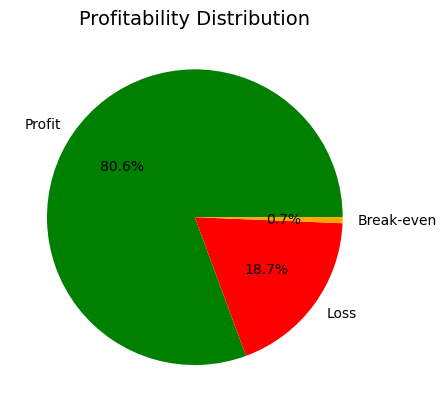

In [117]:
# visualization of profitability distribution......

Profit_counts=df['Profitability_Flag'].value_counts(normalize=True)*100
Profit_counts.plot(kind='pie', autopct='%1.1f%%', colors=['green', 'red', 'orange'])
plt.ylabel('')
plt.title('Profitability Distribution', fontsize=14)
plt.grid(True)
plt.show()

In [118]:
# Business KPIs....

def format_func(value):
    if value>=1e6:
        return f'{value/1e6:.1f}M $'
    elif value>=1e3:
        return f'{value/1e3:.1f}K $'
    else:
        return f'{value:.0f} $'


delayed_df= df[df['Delay']>0]    
metrics={}
metrics['Total Orders']= len(df)
metrics['Late Deliveries']= len(delayed_df)
metrics['90% Delay (days)']= delayed_df['Delay'].quantile(0.90)
metrics['On Time Delivery %']= (1-float(metrics['Late Deliveries'])/ metrics['Total Orders'])*100
metrics['Late Delivery %']= float(metrics['Late Deliveries'])/ metrics['Total Orders']*100
metrics['Total Profit']= format_func(df.loc[df['Order Profit Per Order']>0, 'Order Profit Per Order'].sum())
metrics['Total loss due to delays']=format_func(df.loc[df['Delay']>0, 'Order Profit Per Order'].sum())


print('\n--- Busniess KPIs ---\n')
for key, value in metrics.items():
    if isinstance(value, float):
        print(f'{key}: {value:.2f}')
    else:
        print(f'{key}: {value}')


--- Busniess KPIs ---

Total Orders: 180519
Late Deliveries: 98743
90% Delay (days): 3.00
On Time Delivery %: 45.30
Late Delivery %: 54.70
Total Profit: 7.9M $
Total loss due to delays: 2.1M $


Profitability vs Delivery Time Analysis
---------------------------------------

In [119]:
Profit_metrics=(df.groupby('Delay')['Order Profit Per Order'].agg( mean_profit='mean', total_profit='sum', order_count='count').reset_index())

In [120]:
Profit_metrics

,Delay,mean_profit,total_profit,order_count
0,-2,23.423528,5.074942e+05,21666
1,-1,21.516997,4.669188e+05,21700
2,0,22.044854,8.467429e+05,38410
3,1,22.225592,1.244411e+06,55990
4,2,21.246239,6.101495e+05,28718
5,3,19.941130,1.406248e+05,7052
6,4,21.561202,1.505619e+05,6983


In [121]:
# Delay distribution.....

delay_distribution = (df['Delay'].value_counts(normalize=True).sort_index()*100).reset_index()

delay_distribution

,Delay,proportion
0,-2,12.002061
1,-1,12.020895
2,0,21.277539
3,1,31.016126
4,2,15.908575
5,3,3.906514
6,4,3.868291



Profit Metrics by Delay Day:


,Delay,mean_profit,total_profit,order_count
0,-2,23.4,507494.2,21666
1,-1,21.5,466918.8,21700
2,0,22.0,846742.9,38410
3,1,22.2,1244410.9,55990
4,2,21.2,610149.5,28718
5,3,19.9,140624.8,7052
6,4,21.6,150561.9,6983



Delay Distribution(%):


,Delay_Days,Percentage
0,-2,12.002061
1,-1,12.020895
2,0,21.277539
3,1,31.016126
4,2,15.908575
5,3,3.906514
6,4,3.868291


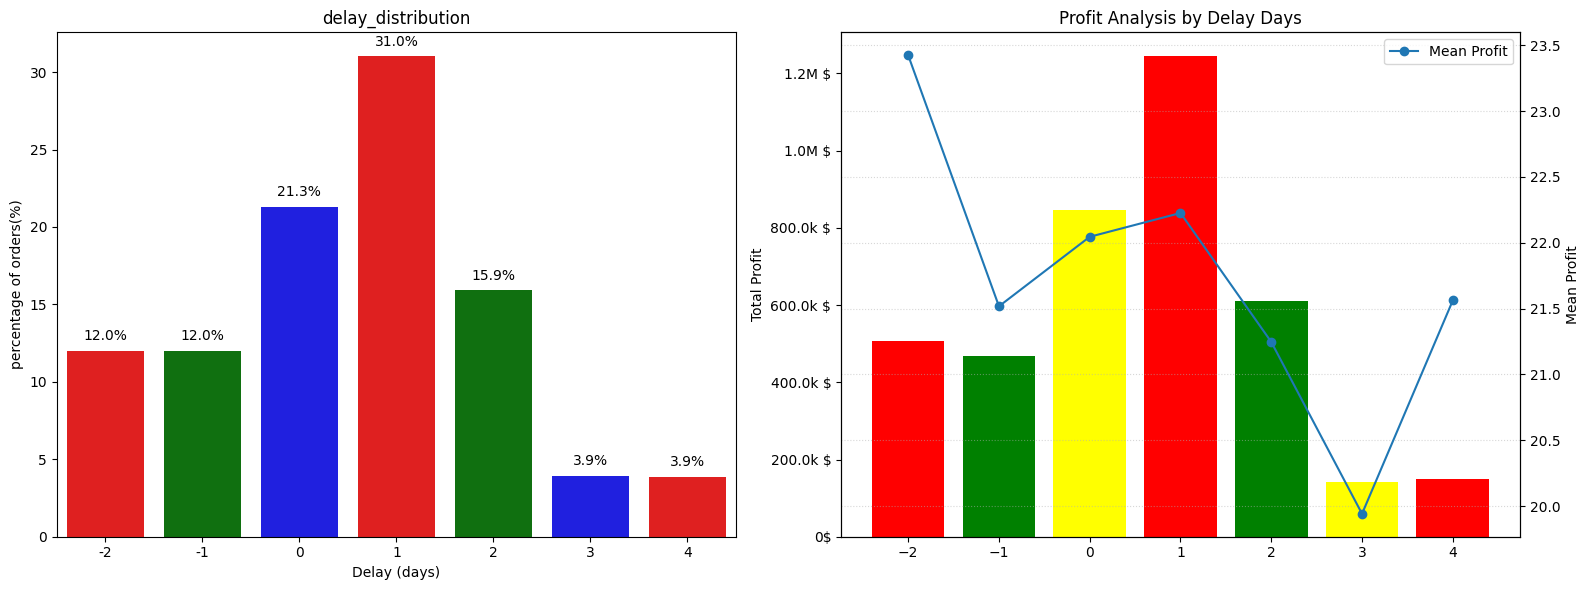

In [122]:
delay_distribution.columns= ['Delay_Days', 'Percentage']

print("\nProfit Metrics by Delay Day:")
display(Profit_metrics.round(1))

print("\nDelay Distribution(%):")
display(delay_distribution)

fig, (ax1, ax2)=plt.subplots(1,2, figsize=(16,6))

#First subplot: Delay Distributtion

sns.barplot(x='Delay_Days', y='Percentage', data= delay_distribution, palette=['red','green', 'blue'], ax=ax1)
ax1.set_title('delay_distribution')
ax1.set_xlabel('Delay (days)')
ax1.set_ylabel('percentage of orders(%)')

# percentage text on bar...

for bar in ax1.patches:
    height=bar.get_height()
    ax1.text(bar.get_x()+ bar.get_width()/2, height+0.5,f'{height:.1f}%', ha='center', va='bottom')



# Second subplot: Profit analysis by delay days......

ax2.set_ylabel("Total Profit")
ax2.bar(Profit_metrics['Delay'], Profit_metrics['total_profit'], color=["red","green", "yellow"])
ax2.tick_params(axis='y')

ax3= ax2.twinx()

ax3.set_xlabel("Delay Days")
ax3.set_ylabel("Mean Profit")
ax3.plot(Profit_metrics['Delay'], Profit_metrics['mean_profit'], marker='o', label="Mean Profit")
ax3.tick_params(axis='y')


# Format total profit axis to k $, M $

def format_func(value, tick_number):
    if value>=1e6:
        return f'{value/1e6:.1f}M $'
    elif value>=1e3:
        return f'{value/1e3:.1f}k $'
    else:
        return f'{value:.0f}$'


ax2.yaxis.set_major_formatter(ticker.FuncFormatter(format_func))    

ax3.set_title("Profit Analysis by Delay Days")

lines, labels= ax3.get_legend_handles_labels()
lines2, labels2= ax2.get_legend_handles_labels()
ax3.legend(lines + lines2, labels+labels2, loc='upper right')
ax3.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

Bottleneck Detection....
========================

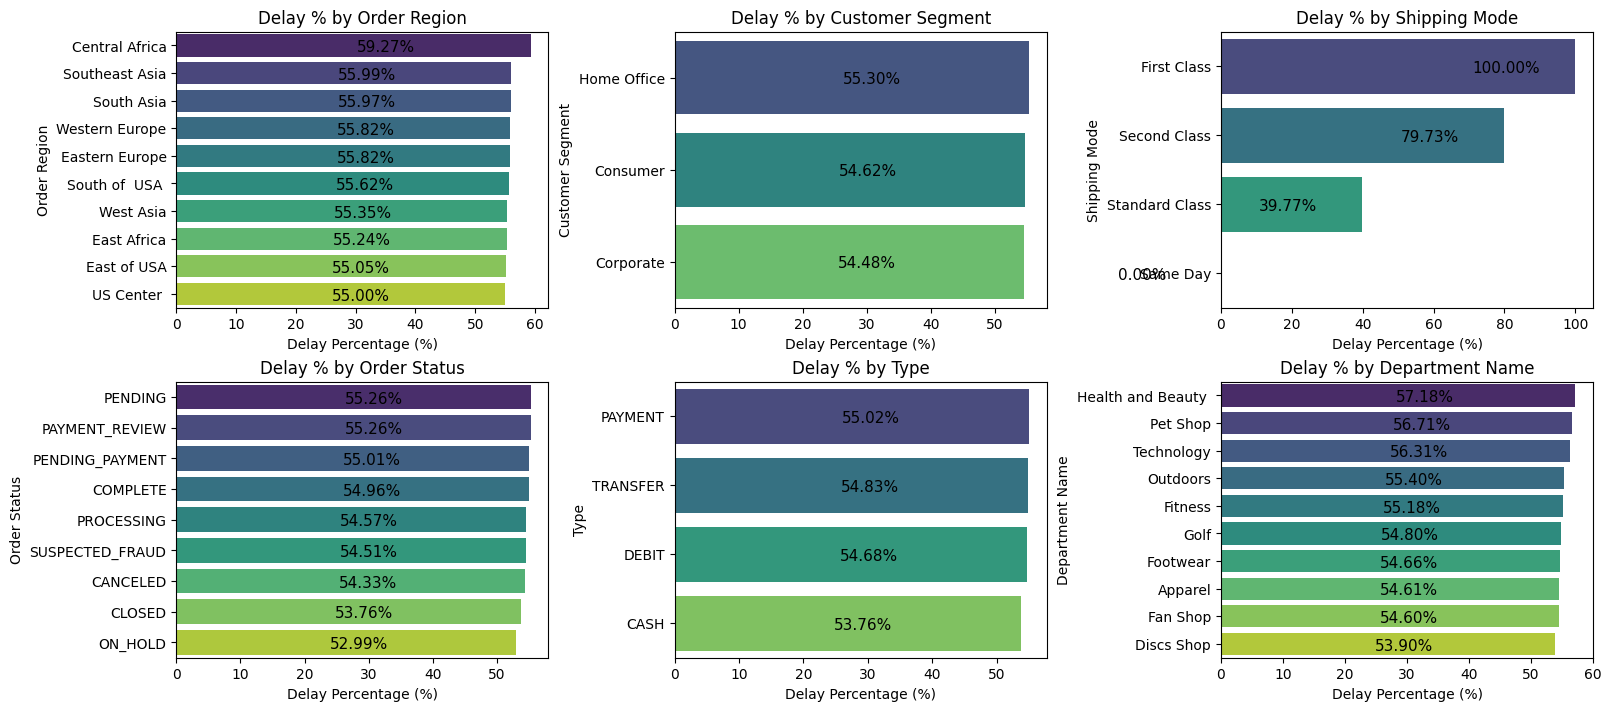

In [123]:
def compute_delay_pct_by_category(category):
    cat_df= df.groupby(category).agg(total_orders=('Delay', 'count'),late_orders=('Is_Delayed', 'sum')).reset_index()
    cat_df['delay_pct']=cat_df['late_orders']/cat_df['total_orders']*100
    cat_df=cat_df.sort_values('delay_pct', ascending=False).head(10)
    return cat_df

categories=['Order Region', 'Customer Segment','Shipping Mode', 'Order Status', 'Type', 'Department Name']

fig, axes= plt.subplots(2,3, figsize=(16, 7), constrained_layout=True)
axes= axes.flatten()



for ax, category in zip(axes, categories):
    cat_df= compute_delay_pct_by_category(category)
    sns.barplot(data=cat_df,x='delay_pct',y=category, ax=ax, palette='viridis')

    for i, value in enumerate(cat_df['delay_pct']):
     ax.text( value -29,       # X position
              i,                 # Y position
            f'{value:.2f}%',   # Label
            va= 'center_baseline',
            fontsize=11
        )

    ax.set_title(f'Delay % by {category}')
    ax.set_xlabel('Delay Percentage (%)')
    ax.set_ylabel(category)

plt.show()
    



Root Cause Analysis....
========================

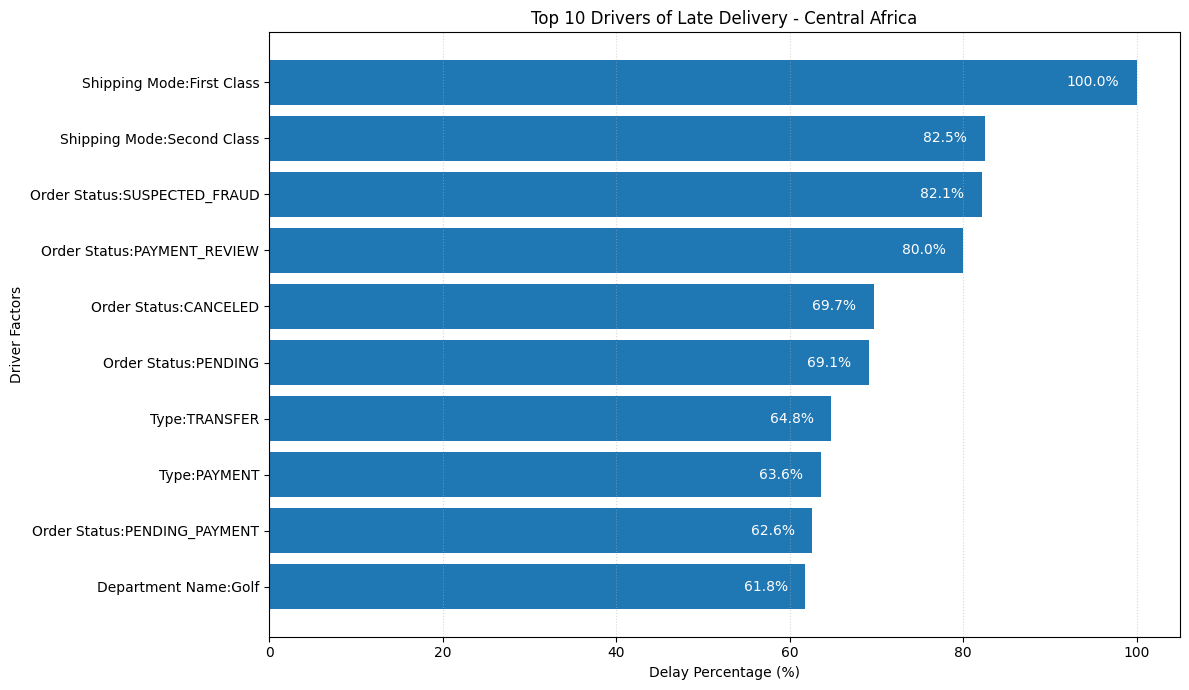

,Driver,Factor_Level,delay_pct,avg_delay,total_orders
11,Department Name,Department Name:Golf,61.781609,0.686782,348
23,Order Status,Order Status:PENDING_PAYMENT,62.576687,0.736196,326
15,Type,Type:PAYMENT,63.583815,0.763006,346
16,Type,Type:TRANSFER,64.830508,0.652542,472
22,Order Status,Order Status:PENDING,69.148936,0.574468,188
17,Order Status,Order Status:CANCELED,69.696970,0.878788,33
21,Order Status,Order Status:PAYMENT_REVIEW,80.000000,1.200000,20
25,Order Status,Order Status:SUSPECTED_FRAUD,82.142857,1.035714,28
2,Shipping Mode,Shipping Mode:Second Class,82.491582,2.127946,297
0,Shipping Mode,Shipping Mode:First Class,100.000000,1.000000,300


In [124]:
# Top drivers of late delivery by region

def top_drivers_for_region(Region):

    # Filter data for selected region
    df_region = df[df['Order Region'] == Region].copy()

    # Drivers to analyze
    drivers = ['Shipping Mode','Customer Segment', 'Department Name', 'Type', 'Order Status']

    all_factors = []

    # Analyze each driver
    for factors in drivers:
        temp = (df_region.groupby(factors).agg( total_orders=('Delay', 'count'),late_orders=('Is_Delayed', 'sum'),avg_delay=('Delay', 'mean')).reset_index())

        # Delay percentage
        temp['delay_pct'] = ( temp['late_orders'] / temp['total_orders'] ) * 100

        # Driver name
        temp['Driver'] = factors

        # Create Driver:Factor label
        temp['Factor_Level'] = (factors + ":" + temp[factors].astype(str))

        # Select columns
        all_factors.append(temp[ ['Driver','Factor_Level','delay_pct','avg_delay','total_orders']])

    # Combine all drivers
    final_df = pd.concat( all_factors, ignore_index=True)

    # Get top 10 drivers
    top_factors = (final_df.sort_values('delay_pct', ascending=False).head(10).sort_values('delay_pct', ascending=True) )

    # -------------------------
    # Plot
    # -------------------------

    plt.figure(figsize=(12, 7))

    bars = plt.barh( top_factors['Factor_Level'], top_factors['delay_pct'])

    plt.xlabel("Delay Percentage (%)")
    plt.ylabel("Driver Factors")
    plt.title( f"Top 10 Drivers of Late Delivery - {Region}")

    plt.grid( True, axis='x', linestyle=':', alpha=0.5)

    # Add percentage labels
    for bar in bars:

        width = bar.get_width()

        plt.text( width - 2, bar.get_y() + bar.get_height() / 2, f"{width:.1f}%", va='center', ha='right',fontsize=10,color='white')

    plt.tight_layout()
    plt.show()

   
    return top_factors


# Run for Central Africa
top_drivers_for_region('Central Africa')

Time Series Analysis........
============================

In [125]:
# Delay percentage by month...


delay_by_month = ( df.groupby('Order_month')['Is_Delayed'].mean().reset_index())

delay_by_month['delay_pct'] = delay_by_month['Is_Delayed'] * 100


# Delay percentage by day...


delay_by_day = ( df.groupby('Order_days')['Is_Delayed'].mean().reset_index())

delay_by_day['delay_pct'] = delay_by_day['Is_Delayed'] * 100


# Delay percentage by hour..


delay_by_hour = (df.groupby('Order_hour')['Is_Delayed'].mean().reset_index())

delay_by_hour['delay_pct'] = delay_by_hour['Is_Delayed'] * 100

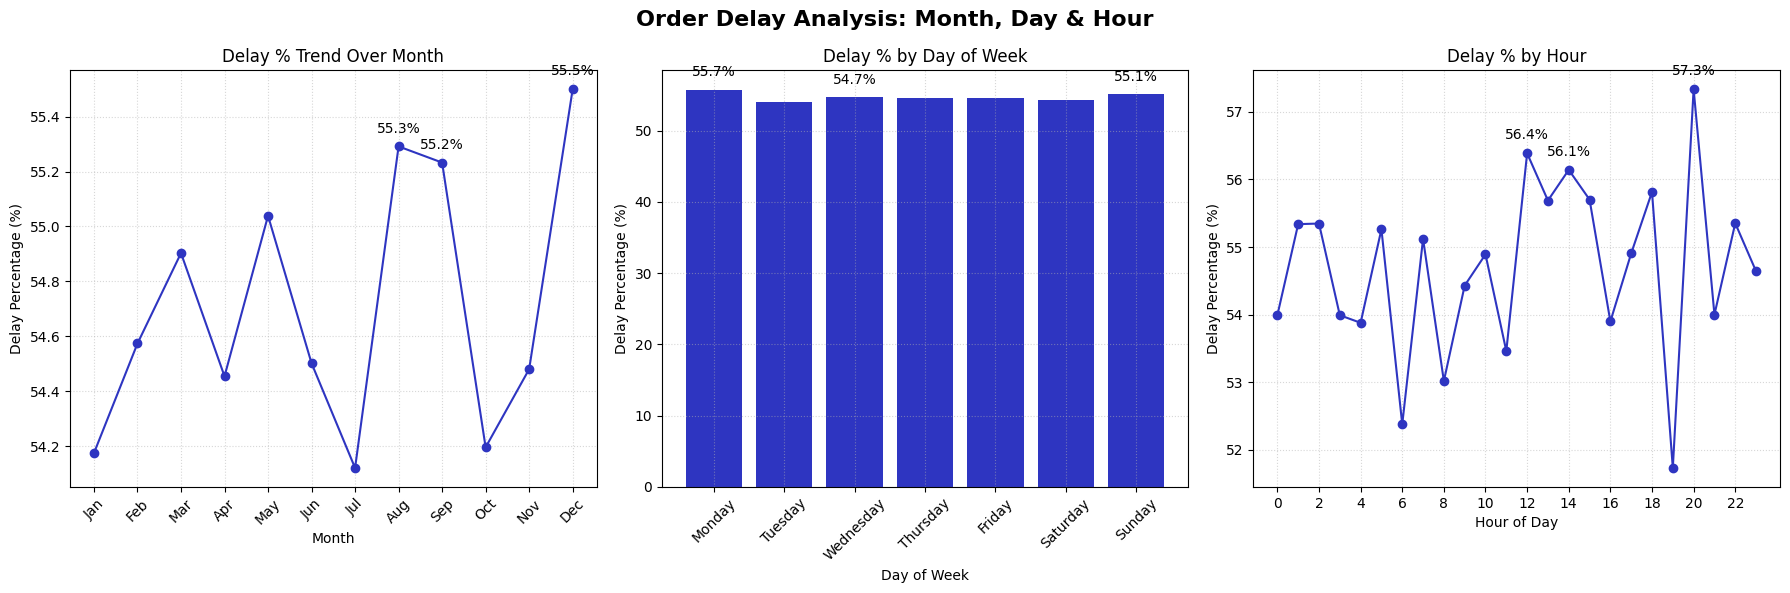

In [126]:
# Colors
primary_color = "#2E35C1"
danger_color = "#000000"

# Create 3 Subplots

fig, (ax1, ax2, ax3) = plt.subplots(1, 3,figsize=(18, 6))

# Subplot 1: Delay % Trend Over Month

delay_by_month = delay_by_month.sort_values("Order_month")

ax1.plot(delay_by_month["Order_month"],delay_by_month["delay_pct"],marker="o",color=primary_color)

ax1.set_xticks(range(1, 13))

ax1.set_xticklabels(["Jan", "Feb", "Mar", "Apr","May", "Jun", "Jul", "Aug","Sep", "Oct", "Nov", "Dec"],rotation=45)

ax1.set_xlabel("Month")
ax1.set_ylabel("Delay Percentage (%)")
ax1.set_title("Delay % Trend Over Month")

ax1.grid(True,linestyle=":",alpha=0.5)


# Annotate Top 3 Highest Months

top3_month = delay_by_month.nlargest(3,"delay_pct")

for _, row in top3_month.iterrows():

 ax1.annotate(f"{row['delay_pct']:.1f}%", (row["Order_month"], row["delay_pct"] ), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=10, color=danger_color)


# Subplot 2: Delay % by Day of Week

day_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]


# Convert Order_days into categorical order

delay_by_day["Order_days"] = pd.Categorical(delay_by_day["Order_days"],categories=day_order,ordered=True)


# Sort by day order

delay_by_day = delay_by_day.sort_values( "Order_days")


ax2.bar( delay_by_day["Order_days"], delay_by_day["delay_pct"], color=primary_color)

ax2.set_xlabel("Day of Week")
ax2.set_ylabel("Delay Percentage (%)")
ax2.set_title("Delay % by Day of Week")

ax2.tick_params( axis="x", rotation=45)

ax2.grid(True, linestyle=":", alpha=0.5)


# Annotate Top 3 Highest Days

top3_day = delay_by_day.nlargest(3,"delay_pct")

for _, row in top3_day.iterrows():

 ax2.annotate( f"{row['delay_pct']:.1f}%", (row["Order_days"],row["delay_pct"]), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=10, color=danger_color)


# Subplot 3: Delay % by Hour

delay_by_hour = delay_by_hour.sort_values("Order_hour")


ax3.plot(delay_by_hour["Order_hour"],delay_by_hour["delay_pct"],marker="o",color=primary_color)

ax3.set_xlabel("Hour of Day")
ax3.set_ylabel("Delay Percentage (%)")
ax3.set_title("Delay % by Hour")


# Show every 2 hours

ax3.set_xticks(range(0, 24, 2))

ax3.grid(True, linestyle=":", alpha=0.5)


# Annotate Top 3 Highest Hours

top3_hour = delay_by_hour.nlargest(3,"delay_pct")

for _, row in top3_hour.iterrows():

 ax3.annotate(f"{row['delay_pct']:.1f}%",( row["Order_hour"], row["delay_pct"]),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=10,
        color=danger_color)

# Overall Layout

plt.suptitle("Order Delay Analysis: Month, Day & Hour",
    fontsize=16,
    fontweight="bold")

plt.tight_layout()

plt.show()

In [127]:
df

,Type,Days for shipping (real),Days for shipment (scheduled),Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer Country,Customer Segment,Department Name,...,Product Price,shipping date (DateOrders),Shipping Mode,Order Processing Time,Delay,Is_Delayed,Order_month,Order_days,Order_hour,Profitability_Flag
0,DEBIT,3,4,314.640015,Advance shipping,0,Sporting Goods,Puerto Rico,Consumer,Fitness,...,327.750000,2018-02-03 22:56:00,Standard Class,3,-1,False,1,Wednesday,22,Profit
1,TRANSFER,5,4,311.359985,Late delivery,1,Sporting Goods,Puerto Rico,Consumer,Fitness,...,327.750000,2018-01-18 12:27:00,Standard Class,5,1,True,1,Saturday,12,Loss
2,CASH,4,4,309.720001,Shipping on time,0,Sporting Goods,EE. UU.,Consumer,Fitness,...,327.750000,2018-01-17 12:06:00,Standard Class,4,0,False,1,Saturday,12,Loss
3,DEBIT,3,4,304.809998,Advance shipping,0,Sporting Goods,EE. UU.,Home Office,Fitness,...,327.750000,2018-01-16 11:45:00,Standard Class,3,-1,False,1,Saturday,11,Profit
4,PAYMENT,2,4,298.250000,Advance shipping,0,Sporting Goods,Puerto Rico,Corporate,Fitness,...,327.750000,2018-01-15 11:24:00,Standard Class,2,-2,False,1,Saturday,11,Profit
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180514,CASH,4,4,399.980011,Shipping on time,0,Fishing,EE. UU.,Home Office,Fan Shop,...,399.980011,2016-01-20 03:40:00,Standard Class,4,0,False,1,Saturday,3,Profit
180515,DEBIT,3,2,395.980011,Late delivery,1,Fishing,EE. UU.,Corporate,Fan Shop,...,399.980011,2016-01-19 01:34:00,Second Class,3,1,True,1,Saturday,1,Loss
180516,TRANSFER,5,4,391.980011,Late delivery,1,Fishing,EE. UU.,Corporate,Fan Shop,...,399.980011,2016-01-20 21:00:00,Standard Class,5,1,True,1,Friday,21,Profit
180517,PAYMENT,3,4,387.980011,Advance shipping,0,Fishing,Puerto Rico,Consumer,Fan Shop,...,399.980011,2016-01-18 20:18:00,Standard Class,3,-1,False,1,Friday,20,Profit


In [129]:
df.to_csv('supply_chain_cleaned.csv', index=False)